# ACF, timescale analysis

## A. Analytical toy model, no noise

Trying to extract parameters from toy model
$$
\hat{C}_1(\tau) = 0.7\,\text{e}^{-\tau/1440} + 0.1\,\text{e}^{-\tau/60} + 0.1\,\text{e}^{-\tau/26} + 0.1\,\text{e}^{-\tau/2}
$$

tau_0: 21.64, tau_int_sokal: 1260.94, tau_int_window: 6305.00, tau_int: 1303.80, t1: 1850.00, a1: 0.70, t1_err: 0.00, a1_err: 0.00, purity: 0.70, t_min: 1999.90, t_max: 19999.00
a1: 0.70, a1_tail: 0.70, t1: 1850.00, tau_R: 28.98, R_window: 300.00, tau_R_resolved: 1.00, gap: 63.84, tau_int: 1303.80, identity_error: 0.53, t_min: 1999.90, t_max: 19999.00, R: ndarray(20000,)


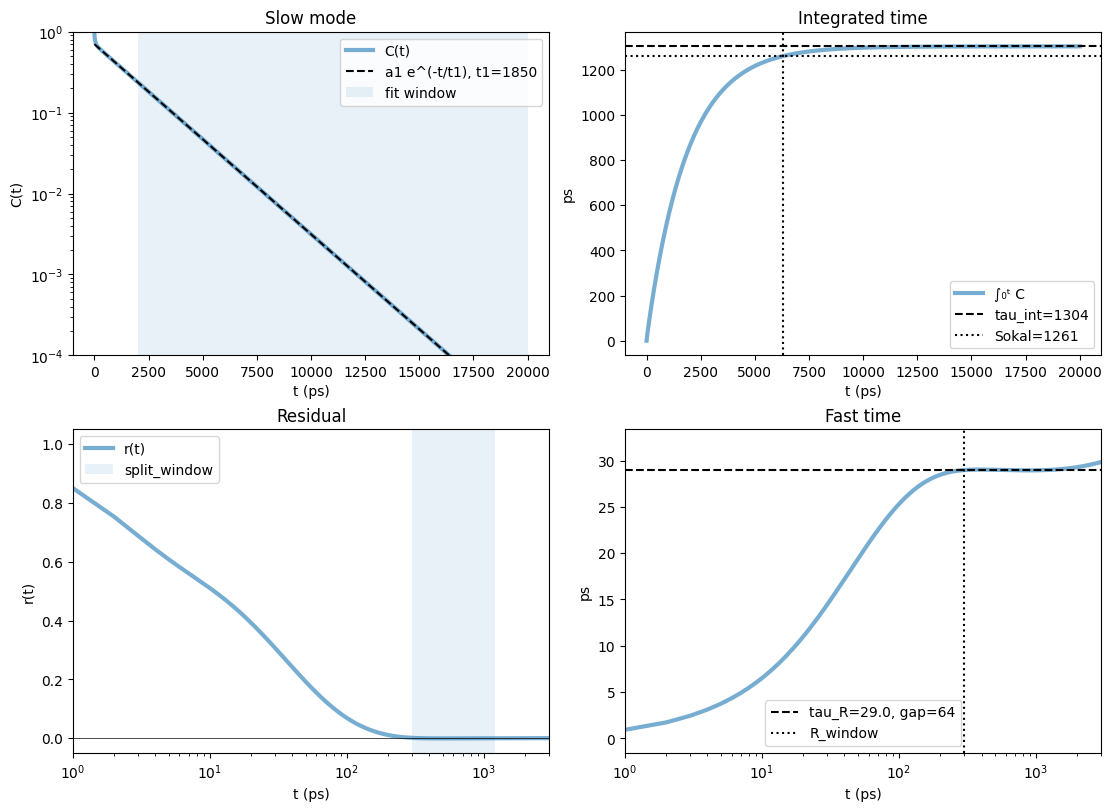

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from vac_metad.paths import DATA
from vac_metad.cached import cached
from vac_metad.acf.toy import toy_model
from vac_metad.acf.analysis import (
    acf_timescales,
    slow_mode_analysis,
    fit_multi_exponential,
)
from vac_metad.plots.acf import plot_timescales_slow_mode

WD = DATA / "toy-model-acf"


@cached(WD, "analysis.pickle")
def analysis(toy):
    return dict(
        acf=toy,
        ts=acf_timescales(toy),
        sm=slow_mode_analysis(toy, split_window=(300.0, 1200.0)),
        multi={
            n: fit_multi_exponential(toy, n, sum_to_one=True, t_max=6000.0)
            for n in (2, 3, 4)
        },
    )


toy = toy_model(frametime=1.0, num_lags=20_000)
r = analysis(toy)  # loads if the file exists, else computes

print(r["ts"])
print(r["sm"])
plot_timescales_slow_mode(r["acf"], r["ts"], r["sm"])

(<Figure size 1600x480 with 3 Axes>,
 (<Axes: xlabel='t', ylabel='C(t)'>,
  <Axes: xlabel='t', ylabel='$|\\hat C - $fit$|$'>,
  <Axes: xlabel='$t_i$', ylabel='$a_i$'>))

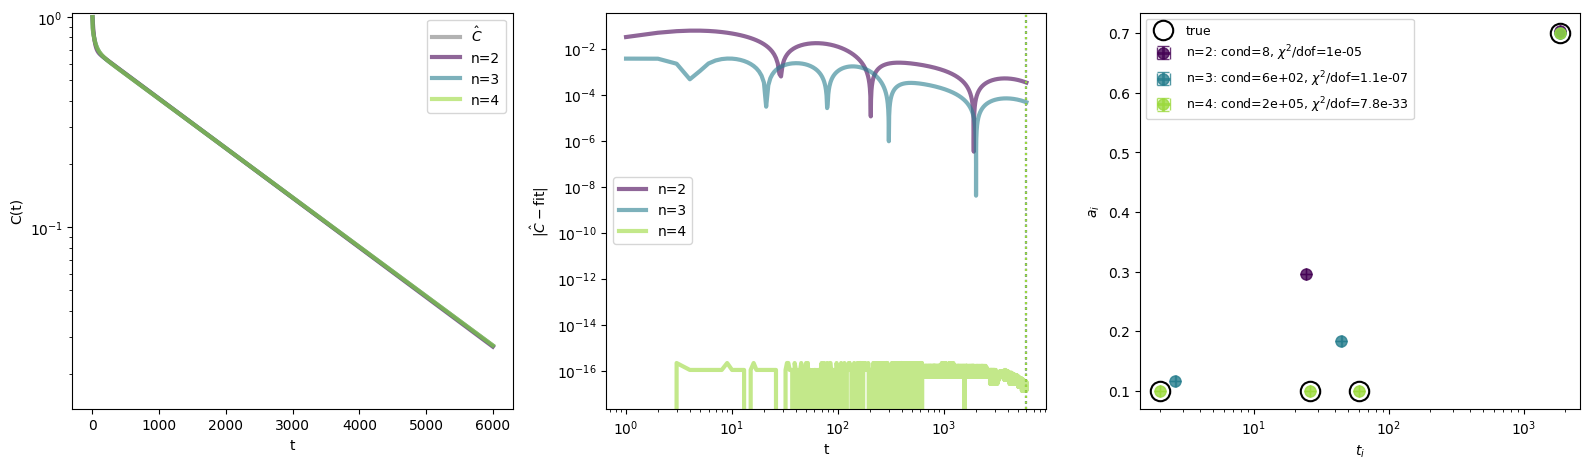

In [ ]:
from vac_metad.plots.acf import plot_multi_fits

plot_multi_fits(toy, r["multi"])